# Ancestor coverage: stdpopsim and 1KGP

In [1]:
import pathlib
import time

import numpy as np
import polars as pl

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()

In [2]:
# Uncomment both alternatives together to run the 10 Mb analysis later.
# All available CPUs; use 1 to avoid process startup on small runs.
match_eval_dir = pathlib.Path("~/work/tsinfer-match-eval/data/match_eval").expanduser()
simulation_dir = pathlib.Path(
    "~/work/tsinfer-anc-eval/data/error_eval/simulated"
).expanduser()
dataset_names = {"stdpopsim": "out_of_africa_n100_1mbp", "1KGP": "tgp_chr20_n100_1mbp"}
simulation_ts = simulation_dir / "OutOfAfrica_4J17-chr20-L0-R1e6-n100-s1-rep0.trees"
dataset_names = {"stdpopsim": "out_of_africa_n100_10mbp", "1KGP": "tgp_chr20_n100"}
simulation_ts = simulation_dir / "OutOfAfrica_4J17-chr20-L0-R1e7-n100-s1-rep0.trees"
max_ac = 200
num_ac_bins = 20
mismatch_budgets = [0, 1]
histogram_ac_cutoffs = [3, 5, 10]
coverage_histogram_bins = np.linspace(0, 1, 21)
workers = None
cutoffs = nb_utils.focal_ac_cutoffs(max_ac=max_ac, num_bins=num_ac_bins)
cutoffs = np.union1d(cutoffs, histogram_ac_cutoffs)
print("Maximum focal AC thresholds:", cutoffs)

Maximum focal AC thresholds: [  2   3   4   5   6   7   9  10  11  14  18  23  29  37  47  60  76  97
 123 157 200]


## Load raw focal-ancestor intervals

Generation anchors each association at its ancestor's leftmost non-padding
focal position, before comparison. Load exact AC and ragged interval arrays;
the analysis applies inclusive AC cutoffs without choosing focal seeds.

In [3]:
coverage_inputs = {}
timings = []
for label, dataset in dataset_names.items():
    started = time.perf_counter()
    truth_path = simulation_ts if label == "stdpopsim" else None
    data = nb_utils.load_coverage_data(
        match_eval_dir,
        dataset,
        max_ac=max_ac,
        max_mismatches=mismatch_budgets,
        truth_ts_path=truth_path,
    )
    coverage_inputs[label] = data
    timings.append(
        {
            "dataset": label,
            "stage": "load_intervals",
            "seconds": time.perf_counter() - started,
        }
    )
    print(
        f"{label}: {data.num_sites:,} inference sites, {data.haplotypes.height} haplotypes, positions {data.first_position:,}–{data.last_position:,}, {len(data.focal_ac):,} associations; budgets {data.mismatch_budgets}"
    )
    print(data.haplotypes.group_by("population").len().sort("population"))

stdpopsim: 44,225 inference sites, 200 haplotypes, positions 81,208–9,999,800, 925,918 associations; budgets [0, 1]
shape: (3, 2)
┌────────────┬─────┐
│ population ┆ len │
│ ---        ┆ --- │
│ str        ┆ u32 │
╞════════════╪═════╡
│ CEU        ┆ 66  │
│ CHB        ┆ 66  │
│ YRI        ┆ 68  │
└────────────┴─────┘


1KGP: 61,798 inference sites, 200 haplotypes, positions 1,000,026–10,999,725, 2,110,059 associations; budgets [0, 1]
shape: (3, 2)
┌────────────┬─────┐
│ population ┆ len │
│ ---        ┆ --- │
│ str        ┆ u32 │
╞════════════╪═════╡
│ AFR        ┆ 68  │
│ EAS        ┆ 66  │
│ EUR        ┆ 66  │
└────────────┴─────┘


## Sweep and summarise coverage

Half-open site intervals `[left_site_index, right_site_index)` contribute +1
at their left endpoint and −1 at their right endpoint. The sweep groups equal
endpoints and incrementally adds associations with `2 ≤ focal_ac ≤ cutoff`,
retaining the existing chapter 5 AC minimum. Constant
coverage segments are weighted by their number of sites, including zero
coverage outside intervals. Each independent haplotype is a multiprocessing task.

The result records mean, minimum, maximum, 5th and 95th percentiles, and the
fraction of sites with coverage > 0 for every haplotype, AC cutoff and budget.
Percentiles (rather than quartiles) use NumPy's usual linear interpolation
across the complete conceptual per-site coverage vector. Endpoint histograms
avoid materialising that vector. Minimum coverage is zero whenever any site
has no candidate, even when the covered fraction is close to one.

In [4]:
coverage_by_budget = {}
for budget in mismatch_budgets:
    coverage_by_budget[budget] = {}
    for label, data in coverage_inputs.items():
        started = time.perf_counter()
        coverage_by_budget[budget][label] = nb_utils.summarise_coverage(
            data, cutoffs, max_mismatches=budget, workers=workers
        )
        timings.append(
            {
                "dataset": label,
                "stage": f"sweep_k{budget}",
                "seconds": time.perf_counter() - started,
            }
        )
print(pl.DataFrame(timings))
coverage_by_budget[0]["stdpopsim"].head()

shape: (6, 3)
┌───────────┬────────────────┬──────────┐
│ dataset   ┆ stage          ┆ seconds  │
│ ---       ┆ ---            ┆ ---      │
│ str       ┆ str            ┆ f64      │
╞═══════════╪════════════════╪══════════╡
│ stdpopsim ┆ load_intervals ┆ 0.086241 │
│ 1KGP      ┆ load_intervals ┆ 0.182443 │
│ stdpopsim ┆ sweep_k0       ┆ 0.881819 │
│ 1KGP      ┆ sweep_k0       ┆ 0.945965 │
│ stdpopsim ┆ sweep_k1       ┆ 0.888346 │
│ 1KGP      ┆ sweep_k1       ┆ 0.956855 │
└───────────┴────────────────┴──────────┘


focal_ac,evaluated_sites,covered_sites,mean_coverage,min_coverage,max_coverage,q05_coverage,q95_coverage,fraction_covered,sample_id,ploidy_index,population,dataset,max_mismatches
i64,i64,i64,f64,i64,i64,f64,f64,f64,str,i64,str,str,i32
2,44225,24647,0.567484,0,2,0.0,1.0,0.557309,"""tsk_0""",0,"""YRI""","""out_of_africa_n100_10mbp""",0
3,44225,33862,0.995839,0,3,0.0,2.0,0.765676,"""tsk_0""",0,"""YRI""","""out_of_africa_n100_10mbp""",0
4,44225,36757,1.273217,0,5,0.0,3.0,0.831136,"""tsk_0""",0,"""YRI""","""out_of_africa_n100_10mbp""",0
5,44225,38401,1.527055,0,5,0.0,3.0,0.86831,"""tsk_0""",0,"""YRI""","""out_of_africa_n100_10mbp""",0
6,44225,38823,1.712606,0,7,0.0,4.0,0.877852,"""tsk_0""",0,"""YRI""","""out_of_africa_n100_10mbp""",0


In [5]:
population_means = {}
for budget, datasets in coverage_by_budget.items():
    population_means[budget] = {}
    for label, coverage in datasets.items():
        means = coverage.group_by("population", "focal_ac").agg(
            pl.col("fraction_covered").mean(),
            pl.col("mean_coverage").mean(),
            pl.len().alias("num_haplotypes"),
        )
        population_means[budget][label] = means.sort("population", "focal_ac")

In [6]:
population_colors = {
    "YRI": "tab:blue",
    "AFR": "tab:blue",
    "CEU": "tab:orange",
    "EUR": "tab:orange",
    "CHB": "tab:green",
    "EAS": "tab:green",
}

## max_mismatches = 0

Exact-match intervals: fraction covered above, mean site coverage below.
Coverage includes every inference site in the denominator.

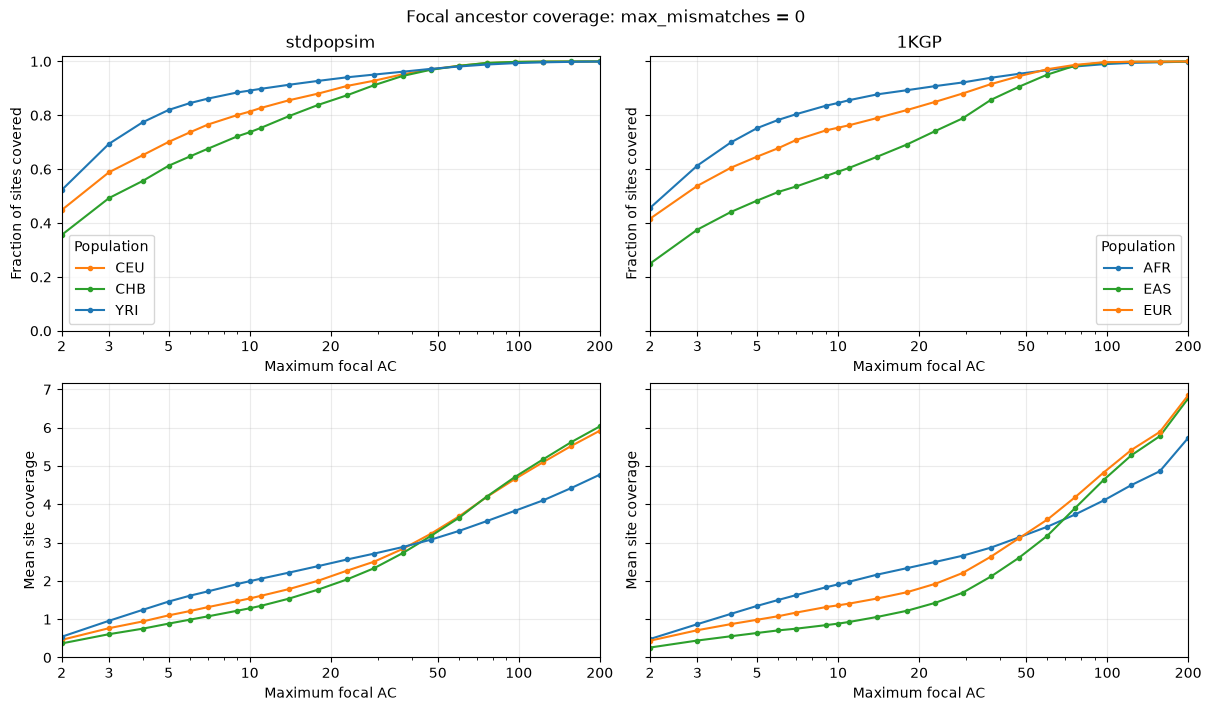

In [7]:
figure_k0 = nb_plot.plot_population_coverage(
    0,
    cutoffs=cutoffs,
    dataset_names=dataset_names,
    max_ac=max_ac,
    population_colors=population_colors,
    population_means=population_means,
)

## max_mismatches = 1

Allow one mismatch on either side of each selected focal site, retaining the
same ancestor/focal choice as for zero mismatches.

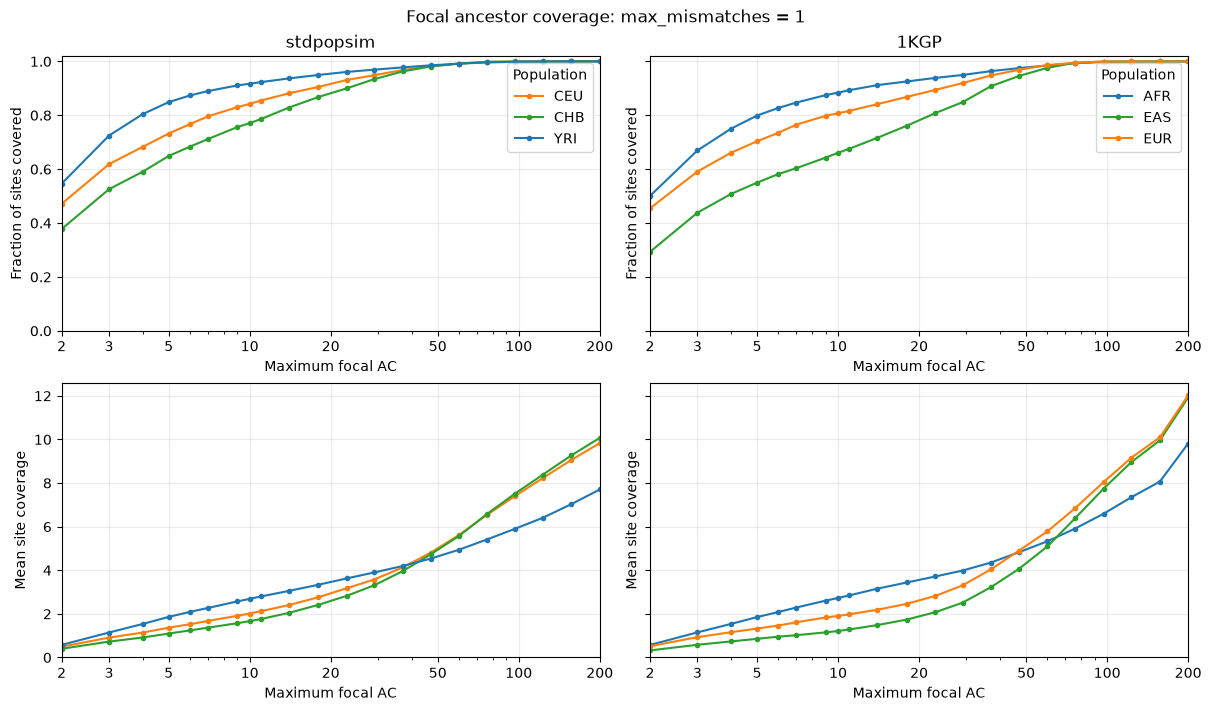

In [8]:
figure_k1 = nb_plot.plot_population_coverage(
    1,
    cutoffs=cutoffs,
    dataset_names=dataset_names,
    max_ac=max_ac,
    population_colors=population_colors,
    population_means=population_means,
)

## Sample coverage histograms: max_mismatches = 0



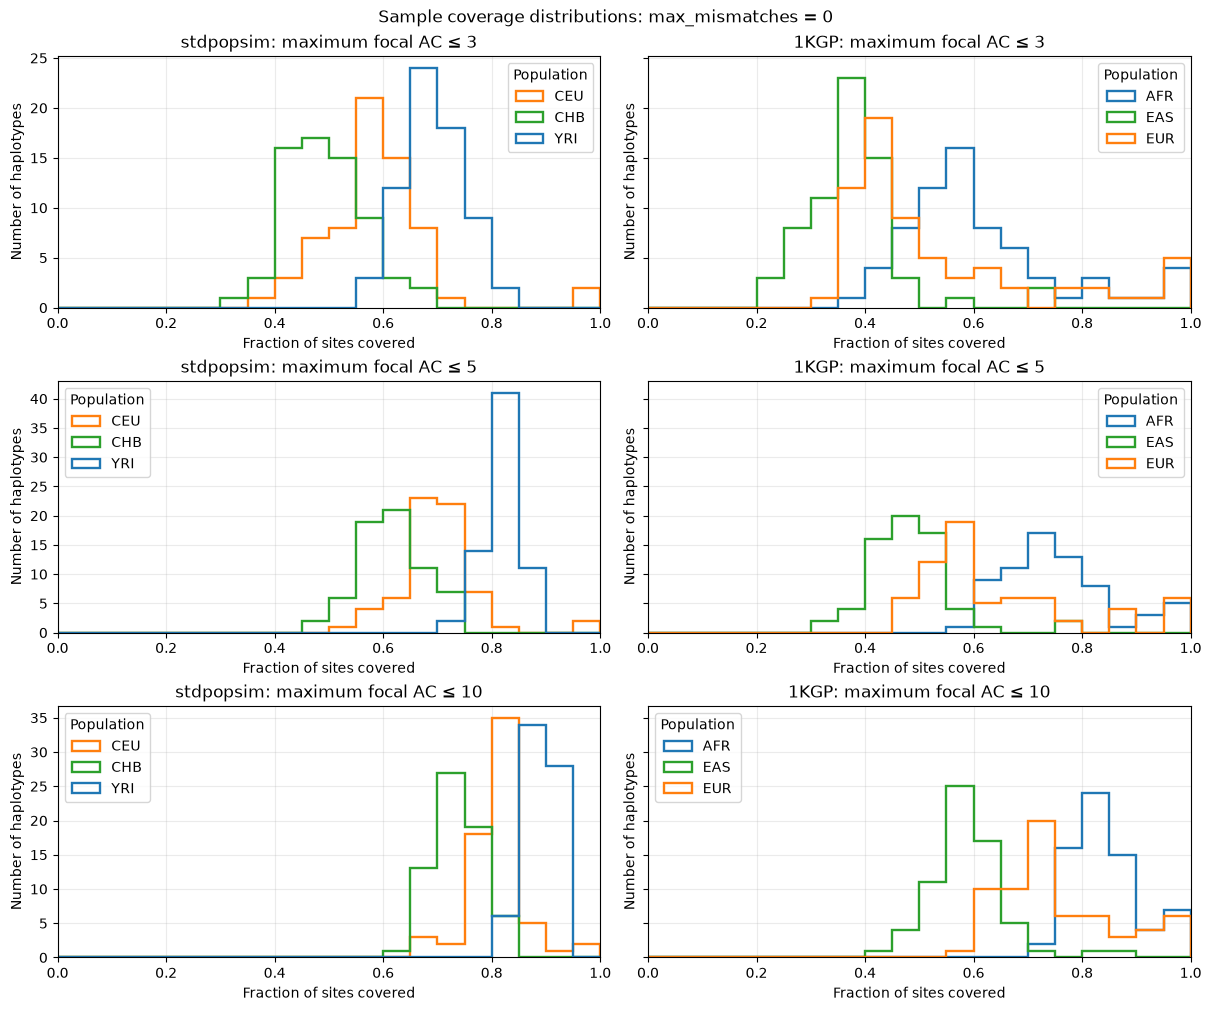

In [10]:
histogram_figure_k0 = nb_plot.plot_population_coverage_histograms(
    0,
    coverage_by_budget=coverage_by_budget,
    coverage_histogram_bins=coverage_histogram_bins,
    dataset_names=dataset_names,
    histogram_ac_cutoffs=histogram_ac_cutoffs,
    population_colors=population_colors,
)

## Sample coverage histograms: max_mismatches = 1

The same cutoffs, bins and population colours, allowing one mismatch per
side of the selected focal site.

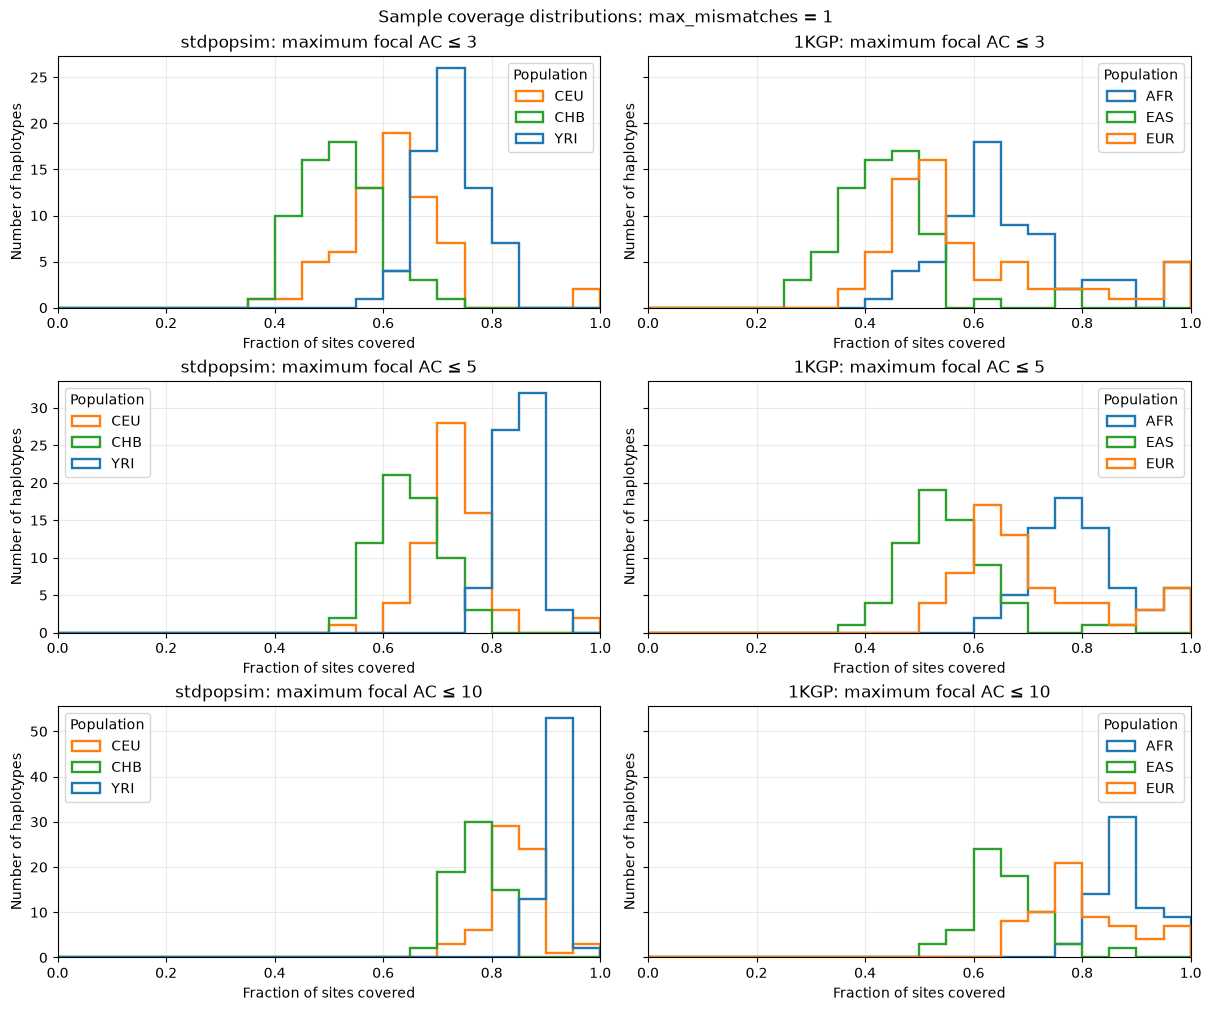

In [11]:
histogram_figure_k1 = nb_plot.plot_population_coverage_histograms(
    1,
    coverage_by_budget=coverage_by_budget,
    coverage_histogram_bins=coverage_histogram_bins,
    dataset_names=dataset_names,
    histogram_ac_cutoffs=histogram_ac_cutoffs,
    population_colors=population_colors,
)

## Mean proportion of ancestors included


In [12]:
ancestor_set_sizes = {}
for label, dataset in dataset_names.items():
    focal_path = (
        match_eval_dir / "focal_ancestors" / f"{dataset}_inferred_focal_ancestors.npz"
    )
    ancestor_set_sizes[label] = nb_utils.summarise_focal_ancestor_set_sizes(
        focal_path, cutoffs
    )

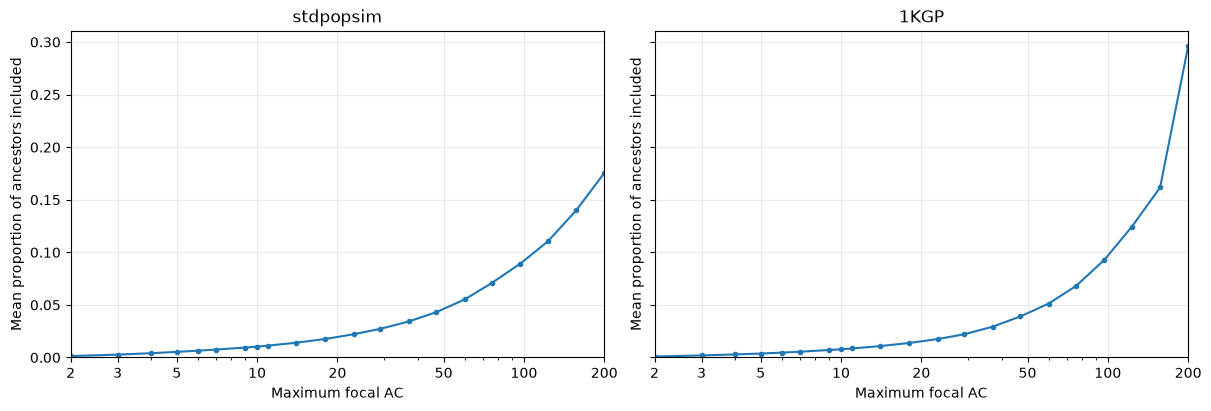

In [13]:
nb_plot.plot_mean_proportion_of_ancestors_included(
    ancestor_set_sizes=ancestor_set_sizes,
    cutoffs=cutoffs,
    dataset_names=dataset_names,
    max_ac=max_ac,
    figsize=(12, 4),
    marker="o",
    markersize=3,
    alpha=0.25,
)